#**Midterm Notebook - DS 2002**

Ayan, Holden, Parker, Andrew

#**Clean Up:**

Loading each CSV and both tables in inventory_and_sales.db. Raw dfs seperate from cleaned data, time stamps = eastern time, later converted to UTC

In [64]:
from pathlib import Path
import re
import sqlite3
import pandas as pd

# paths for both colab & vs code
possible_paths = [
    Path.cwd() / "data",  #cwd
    Path.cwd().parent / "data",  # parent direc
    Path("/content/data"),   # colab data path
]

# check if '/content' (colab)
colab_root = Path("/content")
if colab_root.exists():
    fallback_paths = list(colab_root.glob("**/data"))
    possible_paths.extend(fallback_paths)

DATA_DIR = None
for path in possible_paths:
    if path.is_dir():
        DATA_DIR = path
        break

if DATA_DIR is None:
    # makes local data dir if needed
    DATA_DIR = Path.cwd() / "data"
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    print("Warning: 'data' folder not found. Created an empty 'data' directory.")

DB_PATH = DATA_DIR / "inventory_and_sales.db"
print(f"Data folder configured at: {DATA_DIR.resolve()}")

Data folder configured at: /content/data


loading all csv data as strings, also reading sqlite tables

In [65]:
import os
import pandas as pd
import sqlite3

# schema structures matching what the notebook expects to process
def create_placeholders():
    print("Warning: Real data files not found in /content/data/. Creating empty placeholders to allow code to run...")
    tx = pd.DataFrame(columns=["transaction_id", "store_id", "sku", "product_name", "category", "quantity", "unit_price", "timestamp"])
    prod = pd.DataFrame(columns=["sku", "category", "subcategory", "unit_cost"])
    st = pd.DataFrame(columns=["store_id", "store_name", "city", "state", "region", "latitude", "longitude", "zip_code"])
    dc = pd.DataFrame(columns=["dc_id", "avg_daily_shipments", "surge_capacity", "distance_to_orlando_mi", "cost_per_shipment"])
    inv = pd.DataFrame(columns=["date", "store_id", "sku", "units_on_hand", "units_on_order", "reorder_point"])
    sales = pd.DataFrame(columns=["date", "store_id", "category", "total_units", "total_revenue"])
    return tx, prod, st, dc, inv, sales

try:
    # keep csv values as text while loading
    raw_transactions = pd.read_csv(DATA_DIR / "walmart_transactions.csv", dtype="string", keep_default_na=False)
    raw_products = pd.read_csv(DATA_DIR / "product_catalog.csv", dtype="string", keep_default_na=False)
    raw_stores = pd.read_csv(DATA_DIR / "store_locations.csv", dtype="string", keep_default_na=False)
    raw_distribution_centers = pd.read_csv(DATA_DIR / "distribution_centers.csv", dtype="string", keep_default_na=False)

    # load both tables from the database
    with sqlite3.connect(DB_PATH) as connection:
        raw_inventory = pd.read_sql_query("SELECT * FROM inventory_levels", connection)
        raw_daily_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", connection)
except FileNotFoundError:
    raw_transactions, raw_products, raw_stores, raw_distribution_centers, raw_inventory, raw_daily_sales = create_placeholders()

raw_tables = {
    "transactions": raw_transactions,
    "products": raw_products,
    "stores": raw_stores,
    "distribution_centers": raw_distribution_centers,
    "inventory_levels": raw_inventory,
    "daily_sales_summary": raw_daily_sales,
}

for name, frame in raw_tables.items():
    print(f"{name}: {frame.shape[0]:,} rows x {frame.shape[1]} columns")
    display(frame.head())

transactions: 25,562 rows x 8 columns


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


products: 45 rows x 7 columns


,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


stores: 14 rows x 8 columns


...

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.00
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.50
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.00
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.00
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,


inventory_levels: 4,320 rows x 6 columns


,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


daily_sales_summary: 3,600 rows x 5 columns


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30


data cleaning:
- normalizing null vals, store ids, capializing, spacing, etc. (formatting)
- getting rid of duplicate vals
- standardize products to 1 SKU & product name.
- time stamps localized to NY time and also convert to utc
- converting prices w/ symbols
- "quarantine" negative transactions (seperate from valid values)

In [66]:
MISSING_TOKENS = {"", "NULL", "N/A", "NA", "NAN", "NONE"}

# mark blank and null-like text as missing
def normalize_missing(frame):
    cleaned = frame.copy()
    for column in cleaned.select_dtypes(include=["object", "string"]).columns:
        values = cleaned[column].astype("string").str.strip()
        cleaned[column] = values.mask(values.str.upper().isin(MISSING_TOKENS), pd.NA)
    return cleaned

# put store ids in one format
def normalize_store_id(values):
    text = values.astype("string").str.strip().str.upper()
    parts = text.str.extract(r"^FL[\s_-]?(\d{3})$", expand=False)
    return text.where(parts.isna(), "FL-" + parts)

def normalize_category(values):
    text = values.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    key = text.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    aliases = {
        "breakfastfoods": "Breakfast", "breakfast": "Breakfast",
        "emergencysupplies": "Emergency", "emergency": "Emergency",
        "alcoholicbeverages": "Alcohol", "alcohol": "Alcohol",
        "entertainment": "Entertainment", "electronics": "Electronics",
        "groceries": "Grocery", "grocery": "Grocery",
        "householdessentials": "Household", "household": "Household",
        "babyproducts": "Baby", "baby": "Baby", "health": "Health",
        "snacks": "Snacks",
    }
    return key.map(aliases).fillna(text.str.title()).astype("string")

# remove symbols before converting to numbers
def to_number(values):
    text = values.astype("string").str.strip().str.replace(r"[$,~]", "", regex=True)
    return pd.to_numeric(text, errors="coerce")

def deduplicate(frame, keys, name):
    before = len(frame)
    result = frame.drop_duplicates(subset=keys, keep="first").copy()
    print(f"{name}: removed {before - len(result):,} duplicate rows by {keys}")
    return result

In [67]:
sku_groups = {
    "PT-12": ["PT-12", "SKU#459812", "POPTART-STRAW", "PT_STRAWBERRY"],
    "WTR-24": ["WTR-24", "WATER24PK", "WTR_24PK"],
    "BATT-100": ["BATT-100", "BAT-AA4", "BATT_AA_4PK"],
    "FLASH-01": ["FLASH-01", "LED-FLASH"],
    "BEER-24": ["BEER-24", "LTBEER24"],
    "BG-MONO": ["BG-MONO", "MONOPOLY-01", "GAME-MONO"],
    "CARDS-01": ["CARDS-01", "PLAYCARD-STD"],
    "STREAM-01": ["STREAM-01", "ROKU-STD"],
    "SOUP-CAN": ["SOUP-CAN", "CNSOUP-01"],
    "BREAD-WH": ["BREAD-WH", "WHITEBREAD"],
    "PB-16": ["PB-16", "PNUTBTR-16"],
    "CNDL-EM": ["CNDL-EM", "CANDLE-EMRG"],
    "FAID-01": ["FAID-01", "FIRSTAID-KIT"],
    "CHRG-PORT": ["CHRG-PORT", "PORTCHARGER"],
    "CHIPS-VP": ["CHIPS-VP", "CHIPVARIETY"],
    "PTOWEL-6": ["PTOWEL-6", "PAPERTOWEL6"],
    "TP-12": ["TP-12", "TOILETPAPER12"],
    "DIAP-S3": ["DIAP-S3", "DIAPERS-3"],
    "BFORM-01": ["BFORM-01", "BABYFORMULA"],
    "TARP-HD": ["TARP-HD", "HDTARP-01"],
}
canonical_names = {
    "PT-12": "Strawberry Pop-Tarts", "WTR-24": "Bottled Water 24-Pack",
    "BATT-100": "AA Batteries 4-Pack", "FLASH-01": "LED Flashlight",
    "BEER-24": "Light Beer 24-Pack", "BG-MONO": "Monopoly Board Game",
    "CARDS-01": "Playing Cards", "STREAM-01": "Roku Streaming Stick",
    "SOUP-CAN": "Canned Soup", "BREAD-WH": "White Bread",
    "PB-16": "Peanut Butter", "CNDL-EM": "Emergency Candles",
    "FAID-01": "First Aid Kit", "CHRG-PORT": "Portable Phone Charger",
    "CHIPS-VP": "Chips Variety Pack", "PTOWEL-6": "Paper Towels",
    "TP-12": "Toilet Paper 12-Roll", "DIAP-S3": "Baby Diapers Size 3",
    "BFORM-01": "Infant Formula", "TARP-HD": "Heavy Duty Tarp",
}
sku_to_canonical = {
    alias.strip().upper(): canonical
    for canonical, aliases in sku_groups.items()
    for alias in aliases
}

# check catalog skus before mapping aliases
products = normalize_missing(raw_products)
products["sku"] = products["sku"].astype("string").str.strip().str.upper()
catalog_skus = set(products["sku"].dropna())
unmapped_catalog_skus = sorted(catalog_skus - set(sku_to_canonical))
print(f"catalog SKUs without an explicit alias: {unmapped_catalog_skus}")
assert not unmapped_catalog_skus, "add an explicit canonical mapping for every catalog SKU"

products["canonical_sku"] = products["sku"].map(sku_to_canonical)
products["product_name"] = products["canonical_sku"].map(canonical_names)
products["category"] = normalize_category(products["category"])
products["subcategory"] = products["subcategory"].astype("string").str.strip().str.title()
products["unit_cost"] = to_number(products["unit_cost"])
products = deduplicate(products, ["sku"], "product catalog")

sku_aliases = pd.DataFrame(
    [(alias, canonical, canonical_names[canonical])
     for canonical, aliases in sku_groups.items() for alias in aliases],
    columns=["source_sku", "canonical_sku", "canonical_product_name"],
)
display(sku_aliases.head(12))
display(products.head())

catalog SKUs without an explicit alias: []
product catalog: removed 0 duplicate rows by ['sku']


,source_sku,canonical_sku,canonical_product_name
0,PT-12,PT-12,Strawberry Pop-Tarts
1,SKU#459812,PT-12,Strawberry Pop-Tarts
2,POPTART-STRAW,PT-12,Strawberry Pop-Tarts
3,PT_STRAWBERRY,PT-12,Strawberry Pop-Tarts
4,WTR-24,WTR-24,Bottled Water 24-Pack
5,WATER24PK,WTR-24,Bottled Water 24-Pack
6,WTR_24PK,WTR-24,Bottled Water 24-Pack
7,BATT-100,BATT-100,AA Batteries 4-Pack
8,BAT-AA4,BATT-100,AA Batteries 4-Pack
9,BATT_AA_4PK,BATT-100,AA Batteries 4-Pack


,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku
0,PT-12,Strawberry Pop-Tarts,Breakfast,<NA>,1.93,Johnson & Johnson,4-pack,PT-12
1,SKU#459812,Strawberry Pop-Tarts,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk,PT-12
2,POPTART-STRAW,Strawberry Pop-Tarts,Breakfast,<NA>,2.11,Sara Lee,6 pack,PT-12
3,PT_STRAWBERRY,Strawberry Pop-Tarts,Breakfast,Pop-Tarts,<NA>,Campbell's,4 pack,PT-12
4,WTR-24,Bottled Water 24-Pack,Emergency,Bottled,2.64,Sara Lee,1 pack,WTR-24


In [68]:
# remove repeated transaction ids
transactions = normalize_missing(raw_transactions)
transactions["transaction_id"] = transactions["transaction_id"].astype("string").str.strip().str.upper()
transactions = deduplicate(transactions, ["transaction_id"], "transactions")

transactions["store_id"] = normalize_store_id(transactions["store_id"])
transactions["source_sku"] = transactions["sku"].astype("string").str.strip().str.upper()
transactions["canonical_sku"] = transactions["source_sku"].map(sku_to_canonical).fillna(transactions["source_sku"])
transactions["product_name"] = transactions["canonical_sku"].map(canonical_names).fillna(
    transactions["product_name"].astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.title()
)
transactions["category"] = normalize_category(transactions["category"])
transactions["quantity"] = to_number(transactions["quantity"])
transactions["unit_price"] = to_number(transactions["unit_price"])

# convert local sales times to utc
parsed_timestamps = pd.to_datetime(transactions["timestamp"], format="mixed", errors="coerce")
if parsed_timestamps.dt.tz is None:
    parsed_timestamps = parsed_timestamps.dt.tz_localize(
        "America/New_York", ambiguous="NaT", nonexistent="NaT"
    )
transactions["timestamp_local"] = parsed_timestamps
transactions["timestamp_utc"] = parsed_timestamps.dt.tz_convert("UTC")

# set negative quantities aside for review
negative_quantity_mask = transactions["quantity"].lt(0).fillna(False)
transactions_quarantined = transactions.loc[negative_quantity_mask].copy()
transactions_clean = transactions.loc[~negative_quantity_mask].copy()
print(f"quarantined negative-quantity transactions: {len(transactions_quarantined):,}")
print(f"unparsed or missing timestamps: {transactions_clean['timestamp_utc'].isna().sum():,}")
print(f"missing prices: {transactions_clean['unit_price'].isna().sum():,}")
display(transactions_clean.head())
display(transactions_quarantined.head())

transactions: removed 30 duplicate rows by ['transaction_id']
quarantined negative-quantity transactions: 130
unparsed or missing timestamps: 881
missing prices: 0


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,source_sku,canonical_sku,timestamp_local,timestamp_utc
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,Peanut Butter,Grocery,1,3.15,PNUTBTR-16,PB-16,2024-09-24 09:48:13-04:00,2024-09-24 13:48:13+00:00
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,Canned Soup,Grocery,1,2.02,CNSOUP-01,SOUP-CAN,2024-09-13 20:30:20-04:00,2024-09-14 00:30:20+00:00
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,TOILETPAPER12,TP-12,2024-09-17 10:06:00-04:00,2024-09-17 14:06:00+00:00
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,ROKU-STD,STREAM-01,2024-09-11 06:29:08-04:00,2024-09-11 10:29:08+00:00
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24-Pack,Alcohol,3,18.82,BEER-24,BEER-24,2024-09-26 15:59:42-04:00,2024-09-26 19:59:42+00:00


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,source_sku,canonical_sku,timestamp_local,timestamp_utc
163,TXN008747,FL-078,2024-09-22T21:30:35,PAPERTOWEL6,Paper Towels,Household,-2,7.91,PAPERTOWEL6,PTOWEL-6,2024-09-22 21:30:35-04:00,2024-09-23 01:30:35+00:00
223,TXN006255,FL-619,2024-09-20 17:10:14,DIAPERS-3,Baby Diapers Size 3,Baby,-2,25.79,DIAPERS-3,DIAP-S3,2024-09-20 17:10:14-04:00,2024-09-20 21:10:14+00:00
563,TXN013118,FL-330,09-25-2024 11:32:05,GAME-MONO,Monopoly Board Game,Entertainment,-2,19.58,GAME-MONO,BG-MONO,2024-09-25 11:32:05-04:00,2024-09-25 15:32:05+00:00
811,TXN022136,FL-287,09-06-2024 13:20:05,TP-12,Toilet Paper 12-Roll,Household,-2,9.64,TP-12,TP-12,2024-09-06 13:20:05-04:00,2024-09-06 17:20:05+00:00
1034,TXN018762,FL-619,2024-09-30 14:42:48,FAID-01,First Aid Kit,Health,-2,14.45,FAID-01,FAID-01,2024-09-30 14:42:48-04:00,2024-09-30 18:42:48+00:00


In [69]:
stores = normalize_missing(raw_stores)
stores["store_id"] = normalize_store_id(stores["store_id"])
stores["state"] = stores["state"].astype("string").str.strip().str.upper().replace(
    {"FLORIDA": "FL", "FLA.": "FL"}
)
stores["region"] = stores["region"].astype("string").str.strip().str.title()
stores["latitude"] = to_number(stores["latitude"])
stores["longitude"] = to_number(stores["longitude"])
stores["zip_code"] = stores["zip_code"].astype("string").str.strip().str.zfill(5)
stores = deduplicate(stores, ["store_id"], "store locations")

distribution_centers = normalize_missing(raw_distribution_centers)
for column in ["avg_daily_shipments", "surge_capacity", "distance_to_orlando_mi", "cost_per_shipment"]:
    distribution_centers[column] = to_number(distribution_centers[column])
distribution_centers = deduplicate(distribution_centers, ["dc_id"], "distribution centers")

transactions_clean = transactions_clean.merge(
    stores[["store_id", "store_name", "city", "state", "region"]],
    on="store_id", how="left", validate="many_to_one", suffixes=("", "_store"),
)
print(f"transactions with no matching store: {transactions_clean['store_name'].isna().sum():,}")
display(stores.head())
display(distribution_centers)

store locations: removed 2 duplicate rows by ['store_id']
distribution centers: removed 0 duplicate rows by ['dc_id']
transactions with no matching store: 0


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.292,-81.4076,Central


,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,<NA>


In [70]:
inventory = normalize_missing(raw_inventory)
inventory["store_id"] = normalize_store_id(inventory["store_id"])
inventory["sku"] = inventory["sku"].astype("string").str.strip().str.upper()
inventory["source_sku"] = inventory["sku"]
inventory["canonical_sku"] = inventory["sku"].map(sku_to_canonical).fillna(inventory["sku"])
inventory["date"] = pd.to_datetime(inventory["date"], format="mixed", errors="coerce")
for column in ["units_on_hand", "units_on_order", "reorder_point"]:
    inventory[column] = to_number(inventory[column]).astype("Int64")
inventory = deduplicate(inventory, ["date", "store_id", "sku"], "inventory levels")
# combine sku aliases for each store and date
inventory = inventory.groupby(
    ["date", "store_id", "canonical_sku"], as_index=False, dropna=False
).agg(
    units_on_hand=("units_on_hand", "sum"),
    units_on_order=("units_on_order", "sum"),
    reorder_point=("reorder_point", "sum"),
    source_skus=("source_sku", lambda values: ", ".join(sorted(set(values.dropna())))),
)

daily_sales = normalize_missing(raw_daily_sales)
daily_sales["store_id"] = normalize_store_id(daily_sales["store_id"])
daily_sales["date"] = pd.to_datetime(daily_sales["date"], format="mixed", errors="coerce")
daily_sales["category"] = normalize_category(daily_sales["category"])
for column in ["total_units", "total_revenue"]:
    daily_sales[column] = to_number(daily_sales[column])
daily_sales = deduplicate(daily_sales, ["date", "store_id", "category"], "daily sales summary")

display(inventory.head())
display(daily_sales.head())

inventory levels: removed 0 duplicate rows by ['date', 'store_id', 'sku']
daily sales summary: removed 0 duplicate rows by ['date', 'store_id', 'category']


,date,store_id,canonical_sku,units_on_hand,units_on_order,reorder_point,source_skus
0,2024-09-01,FL-078,BEER-24,98,106,53,"BEER-24, LTBEER24"
1,2024-09-01,FL-078,BG-MONO,88,92,27,MONOPOLY-01
2,2024-09-01,FL-078,BREAD-WH,41,62,45,BREAD-WH
3,2024-09-01,FL-078,CARDS-01,25,73,22,CARDS-01
4,2024-09-01,FL-078,DIAP-S3,90,0,42,DIAPERS-3


,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.3


- missing fields are still missing
- transactions_quarantined has negative/null values, transactions_clean has the valid data
- time converted to utc

In [71]:
import pandas as pd

# fallback initialization
_transactions_clean = globals().get("transactions_clean", pd.DataFrame())
_transactions_quarantined = globals().get("transactions_quarantined", pd.DataFrame())
_products = globals().get("products", pd.DataFrame())
_stores = globals().get("stores", pd.DataFrame())
_distribution_centers = globals().get("distribution_centers", pd.DataFrame())
_inventory = globals().get("inventory", pd.DataFrame())
_daily_sales = globals().get("daily_sales", pd.DataFrame())
_sku_to_canonical = globals().get("sku_to_canonical", {})

# check the cleaned data (if data is populated)
if len(_transactions_clean) > 0:
    assert _transactions_clean["transaction_id"].is_unique
    assert _transactions_clean["quantity"].dropna().ge(0).all()
    assert _transactions_clean["timestamp_utc"].dt.tz is not None

if len(_products) > 0:
    assert _products["sku"].isin(_sku_to_canonical).all()

if len(_stores) > 0:
    assert _stores["store_id"].is_unique

quality_summary = pd.DataFrame({
    "dataset": list(raw_tables),
    "raw_rows": [len(frame) for frame in raw_tables.values()],
    "clean_rows": [len(_transactions_clean), len(_products), len(_stores),
                   len(_distribution_centers), len(_inventory), len(_daily_sales)],
})
display(quality_summary)
print("canonical product count:", _products["canonical_sku"].nunique() if len(_products) > 0 else 0)
print("transactions retained:", f"{len(_transactions_clean):,}")
print("transactions quarantined:", f"{len(_transactions_quarantined):,}")
print("stores without coordinates:", int(_stores[["latitude", "longitude"]].isna().any(axis=1).sum()) if len(_stores) > 0 else 0)
if len(_transactions_clean) > 0:
    display(_transactions_clean[["transaction_id", "timestamp_local", "timestamp_utc", "store_id",
                                "canonical_sku", "product_name", "category", "quantity", "unit_price"]].head(10))

,dataset,raw_rows,clean_rows
0,transactions,25562,25402
1,products,45,45
2,stores,14,12
3,distribution_centers,5,5
4,inventory_levels,4320,3726
5,daily_sales_summary,3600,3600


canonical product count: 20
transactions retained: 25,402
transactions quarantined: 130
stores without coordinates: 1


,transaction_id,timestamp_local,timestamp_utc,store_id,canonical_sku,product_name,category,quantity,unit_price
0,TXN012636,2024-09-24 09:48:13-04:00,2024-09-24 13:48:13+00:00,FL-710,PB-16,Peanut Butter,Grocery,1,3.15
1,TXN000759,2024-09-13 20:30:20-04:00,2024-09-14 00:30:20+00:00,FL-412,SOUP-CAN,Canned Soup,Grocery,1,2.02
2,TXN003338,2024-09-17 10:06:00-04:00,2024-09-17 14:06:00+00:00,FL-105,TP-12,Toilet Paper 12-Roll,Household,2,10.47
3,TXN025020,2024-09-11 06:29:08-04:00,2024-09-11 10:29:08+00:00,FL-330,STREAM-01,Roku Streaming Stick,Electronics,1,28.59
4,TXN015797,2024-09-26 15:59:42-04:00,2024-09-26 19:59:42+00:00,FL-302,BEER-24,Light Beer 24-Pack,Alcohol,3,18.82
5,TXN010403,2024-09-23 10:32:34-04:00,2024-09-23 14:32:34+00:00,FL-445,CHIPS-VP,Chips Variety Pack,Snacks,1,8.75
6,TXN014974,2024-09-26 09:26:00-04:00,2024-09-26 13:26:00+00:00,FL-105,TARP-HD,Heavy Duty Tarp,Emergency,2,19.48
7,TXN008161,2024-09-22 14:47:00-04:00,2024-09-22 18:47:00+00:00,FL-330,PTOWEL-6,Paper Towels,Household,2,7.94
8,TXN023517,2024-09-08 16:40:14-04:00,2024-09-08 20:40:14+00:00,FL-619,STREAM-01,Roku Streaming Stick,Electronics,1,30.64
9,TXN012652,2024-09-24 20:03:00-04:00,2024-09-25 00:03:00+00:00,FL-710,CNDL-EM,Emergency Candles,Emergency,3,5.95


# **Weather API:**

pulling real weather for every store and joining it onto daily sales
- source: open-meteo historical weather api, base url https://archive-api.open-meteo.com/v1/archive (no api key)
- hourly precipitation (mm), wind speed (km/h), and barometric pressure (pressure_msl, hPa) at each store's coordinates
- pulled in utc on purpose, then converted to America/New_York (EST) before cutting days. the brief says EST but sept 2024 is daylight time (EDT, utc-4), so a fixed utc-5 would put every hour off by one
- open-meteo stamps rain at the end of the hour, so the rain stamped at midnight counts toward the day before
- sales dated by eastern time, not utc, so evening sales stay on the right day
- pensacola (FL-710) is on central time, treated as eastern like the other stores since the brief gives one sales timezone
- left join so no sales day disappears, checked with row counts and unit totals. days with no weather stay in as NaN as dropping them brings down n in q3 sample
- no fallback data, if the api call fails the notebook says so and weather stays empty

In [72]:
import time
import requests

# open-meteo historical weather api
WEATHER_BASE_URL = "https://archive-api.open-meteo.com/v1/archive"
WEATHER_VARIABLES = ["precipitation", "wind_speed_10m", "pressure_msl"]
RETRY_STATUSES = {429, 500, 502, 503, 504}

# one extra day so sept 30 eastern is fully covered in utc
WEATHER_START = "2024-09-01"
WEATHER_END = "2024-10-01"

# empty weather table if the api can't be reached
def empty_hourly_weather():
    weather = pd.DataFrame(columns=["store_id"] + WEATHER_VARIABLES + ["time_utc", "source"])
    weather[WEATHER_VARIABLES] = weather[WEATHER_VARIABLES].astype("float64")
    weather["time_utc"] = pd.to_datetime(weather["time_utc"], utc=True)
    return weather

# one api call for all stores (comma separated lat/lon)
def fetch_hourly_weather(coordinates, start, end, tries=3):
    params = {
        "latitude": ",".join(coordinates["latitude"].astype(str)),
        "longitude": ",".join(coordinates["longitude"].astype(str)),
        "start_date": start,
        "end_date": end,
        "hourly": ",".join(WEATHER_VARIABLES),
        "timezone": "GMT",  # utc, converted to eastern in the next cell
    }
    for attempt in range(1, tries + 1):
        try:
            response = requests.get(WEATHER_BASE_URL, params=params, timeout=30)
        except (requests.ConnectionError, requests.Timeout):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if response.status_code in RETRY_STATUSES and attempt < tries:
            time.sleep(2 ** attempt)
            continue
        response.raise_for_status()
        break

    locations = response.json()
    if isinstance(locations, dict):  # a single store comes back as one object, not a list
        locations = [locations]
    assert len(locations) == len(coordinates), "api returned a different number of locations"

    frames = []
    for store_id, latitude, location in zip(coordinates["store_id"], coordinates["latitude"], locations):
        # api snaps to its grid, so check each result is near its store
        assert abs(location["latitude"] - latitude) < 0.5, f"location order mismatch at {store_id}"
        assert location["utc_offset_seconds"] == 0, "expected utc times from the api"
        frame = pd.DataFrame(location["hourly"])
        frame.insert(0, "store_id", store_id)
        frames.append(frame)
    hourly = pd.concat(frames, ignore_index=True)
    hourly["store_id"] = hourly["store_id"].astype("string")
    hourly = hourly.rename(columns={"time": "time_utc"})
    hourly["time_utc"] = pd.to_datetime(hourly["time_utc"]).dt.tz_localize("UTC")
    hourly["source"] = "open-meteo"
    return hourly

# tallahassee (FL-619) has no coordinates, use the city center
store_coordinates = stores[["store_id", "city", "latitude", "longitude"]].copy()
needs_fill = store_coordinates["store_id"].eq("FL-619") & store_coordinates["latitude"].isna()
store_coordinates.loc[needs_fill, ["latitude", "longitude"]] = [30.4383, -84.2807]
filled_coordinate_stores = store_coordinates.loc[needs_fill, "store_id"].tolist()
no_coordinates = store_coordinates[["latitude", "longitude"]].isna().any(axis=1)
store_coordinates = store_coordinates.loc[~no_coordinates].reset_index(drop=True)
print(f"filled coordinates for: {filled_coordinate_stores}")
print(f"stores still missing coordinates, skipped: {int(no_coordinates.sum())}")

if store_coordinates.empty:
    print("Warning: no store coordinates loaded, skipping the weather api call.")
    weather_hourly = empty_hourly_weather()
else:
    try:
        weather_hourly = fetch_hourly_weather(store_coordinates, WEATHER_START, WEATHER_END)
    except Exception as error:
        print(f"Warning: weather api call failed ({error}). Leaving weather empty.")
        weather_hourly = empty_hourly_weather()

print(f"weather source: {WEATHER_BASE_URL}")
print(f"stores requested: {len(store_coordinates)}, hourly rows returned: {len(weather_hourly):,}")
display(weather_hourly.head())

filled coordinates for: ['FL-619']
stores still missing coordinates, skipped: 0
weather source: https://archive-api.open-meteo.com/v1/archive
stores requested: 12, hourly rows returned: 8,928


,store_id,time_utc,precipitation,wind_speed_10m,pressure_msl,source
0,FL-239,2024-09-01 00:00:00+00:00,0.0,7.2,1014.1,open-meteo
1,FL-239,2024-09-01 01:00:00+00:00,0.0,6.8,1014.5,open-meteo
2,FL-239,2024-09-01 02:00:00+00:00,0.0,10.3,1015.1,open-meteo
3,FL-239,2024-09-01 03:00:00+00:00,0.0,8.9,1015.1,open-meteo
4,FL-239,2024-09-01 04:00:00+00:00,0.0,7.9,1015.2,open-meteo


In [73]:
SALES_START = pd.Timestamp("2024-09-01")
SALES_END = pd.Timestamp("2024-09-30")

# hourly utc weather -> one row per store and eastern day
def daily_weather(hourly):
    assert hourly[WEATHER_VARIABLES].notna().all().all(), "api returned null hourly values"
    hourly = hourly.sort_values(["store_id", "time_utc"]).reset_index(drop=True)
    hourly["date"] = hourly["time_utc"].dt.tz_convert("America/New_York").dt.tz_localize(None).dt.normalize()
    # open-meteo stamps rain at the end of the hour, so take each hour's rain from the next row
    hourly["rain_in_hour"] = hourly.groupby("store_id")["precipitation"].shift(-1)
    daily = hourly.groupby(["store_id", "date"], as_index=False).agg(
        precipitation_mm=("rain_in_hour", "sum"),
        max_wind_kmh=("wind_speed_10m", "max"),
        min_pressure_hpa=("pressure_msl", "min"),
        hours=("time_utc", "size"),
        rain_hours=("rain_in_hour", "count"),
        source=("source", "first"),
    )
    # drop the partial days from the extra padding
    daily = daily[daily["date"].between(SALES_START, SALES_END)].reset_index(drop=True)
    assert not daily.duplicated(["store_id", "date"]).any(), "more than one weather row per store and day"
    assert daily["hours"].eq(24).all() and daily["rain_hours"].eq(24).all(), "some store-days are missing hours"
    return daily

# show the conversion, the first 4 utc hours of each day are still the day before in eastern time
weather_hourly["time_local"] = weather_hourly["time_utc"].dt.tz_convert("America/New_York")
shifted_weather_hours = int((weather_hourly["time_local"].dt.date != weather_hourly["time_utc"].dt.date).sum())
print(f"hourly weather rows that fall on a different day in eastern time: {shifted_weather_hours:,}")
display(weather_hourly[["store_id", "time_utc", "time_local"]].head())

weather_daily = daily_weather(weather_hourly)
trimmed_weather_hours = len(weather_hourly) - int(weather_daily["hours"].sum())
print(f"padded hours trimmed: {trimmed_weather_hours:,}")
print(f"weather_daily: {len(weather_daily):,} rows "
      f"({weather_daily['store_id'].nunique()} stores x {weather_daily['date'].nunique()} days)")
display(weather_daily.head())

hourly weather rows that fall on a different day in eastern time: 1,488


,store_id,time_utc,time_local
0,FL-239,2024-09-01 00:00:00+00:00,2024-08-31 20:00:00-04:00
1,FL-239,2024-09-01 01:00:00+00:00,2024-08-31 21:00:00-04:00
2,FL-239,2024-09-01 02:00:00+00:00,2024-08-31 22:00:00-04:00
3,FL-239,2024-09-01 03:00:00+00:00,2024-08-31 23:00:00-04:00
4,FL-239,2024-09-01 04:00:00+00:00,2024-09-01 00:00:00-04:00


padded hours trimmed: 288
weather_daily: 360 rows (12 stores x 30 days)


,store_id,date,precipitation_mm,max_wind_kmh,min_pressure_hpa,hours,rain_hours,source
0,FL-078,2024-09-01,1.5,11.3,1011.9,24,24,open-meteo
1,FL-078,2024-09-02,2.9,8.3,1011.9,24,24,open-meteo
2,FL-078,2024-09-03,8.0,16.3,1013.9,24,24,open-meteo
3,FL-078,2024-09-04,15.6,15.3,1016.8,24,24,open-meteo
4,FL-078,2024-09-05,13.3,13.8,1015.4,24,24,open-meteo


In [74]:
# date sales by eastern time (utc would push evening sales to the next day)
sales_for_weather = transactions_clean.dropna(subset=["timestamp_local"]).copy()
no_timestamp_rows = len(transactions_clean) - len(sales_for_weather)
sales_for_weather["date"] = sales_for_weather["timestamp_local"].dt.tz_localize(None).dt.normalize()
utc_date = sales_for_weather["timestamp_utc"].dt.tz_localize(None).dt.normalize()
utc_shifted_rows = int((utc_date != sales_for_weather["date"]).sum())
print(f"transactions with no timestamp, left out of daily tables: {no_timestamp_rows:,}")
print(f"transactions that would move to the next day if dated by utc: {utc_shifted_rows:,} "
      f"({utc_shifted_rows / max(len(sales_for_weather), 1):.1%})")

# category labels the product catalog doesn't use
extra_categories = sorted(set(sales_for_weather["category"].dropna()) - set(products["category"].dropna()))
print(f"categories not in the product catalog: {extra_categories}")

daily_store_sales = sales_for_weather.groupby(["store_id", "date"], as_index=False).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "size"),
)
# same thing split by category
daily_category_sales = sales_for_weather.groupby(["store_id", "date", "category"], as_index=False).agg(
    units=("quantity", "sum"),
    transactions=("transaction_id", "size"),
)
assert daily_store_sales["units"].sum() == sales_for_weather["quantity"].sum(), "store-day rollup lost units"
assert daily_category_sales["units"].sum() == sales_for_weather["quantity"].sum(), "category rollup lost units"
print(f"daily_store_sales: {len(daily_store_sales):,} rows, daily_category_sales: {len(daily_category_sales):,} rows")
display(daily_store_sales.head())

transactions with no timestamp, left out of daily tables: 881
transactions that would move to the next day if dated by utc: 4,381 (17.9%)
categories not in the product catalog: ['Games & Entertainment', 'Health & Wellness']
daily_store_sales: 360 rows, daily_category_sales: 4,045 rows


,store_id,date,units,transactions
0,FL-078,2024-09-01,77,42
1,FL-078,2024-09-02,103,49
2,FL-078,2024-09-03,101,47
3,FL-078,2024-09-04,84,46
4,FL-078,2024-09-05,90,43


In [75]:
# left join weather onto sales and check nothing changed
def join_weather(sales_frame, name):
    joined = sales_frame.merge(
        weather_daily, on=["store_id", "date"], how="left",
        validate="many_to_one", indicator=True,
    )
    print(f"{name}: {joined['_merge'].value_counts().to_dict()}")
    assert len(joined) == len(sales_frame), f"{name}: join changed the row count"
    assert not joined["_merge"].eq("right_only").any(), f"{name}: right_only rows present"
    assert joined["units"].sum() == sales_frame["units"].sum(), f"{name}: join changed total units"
    print(f"{name}: {len(sales_frame):,} rows before, {len(joined):,} after, units unchanged")
    joined["has_weather"] = joined["_merge"].eq("both")
    return joined.drop(columns="_merge")

store_day_weather = join_weather(daily_store_sales, "store-day sales")
category_day_weather = join_weather(daily_category_sales, "store-day-category sales")

# sales days with no weather
unmatched_sales_days = store_day_weather.loc[~store_day_weather["has_weather"], ["store_id", "date"]]
print(f"store-days with no weather: {len(unmatched_sales_days)}")
if len(unmatched_sales_days) > 0:
    display(unmatched_sales_days)

# weather days with no sales
weather_without_sales = len(weather_daily) - int(store_day_weather["has_weather"].sum())
print(f"store-days with weather but no sales: {weather_without_sales}")
display(store_day_weather.head())

store-day sales: {'both': 360, 'left_only': 0, 'right_only': 0}
store-day sales: 360 rows before, 360 after, units unchanged
store-day-category sales: {'both': 4045, 'left_only': 0, 'right_only': 0}
store-day-category sales: 4,045 rows before, 4,045 after, units unchanged
store-days with no weather: 0
store-days with weather but no sales: 0


,store_id,date,units,transactions,precipitation_mm,max_wind_kmh,min_pressure_hpa,hours,rain_hours,source,has_weather
0,FL-078,2024-09-01,77,42,1.5,11.3,1011.9,24,24,open-meteo,True
1,FL-078,2024-09-02,103,49,2.9,8.3,1011.9,24,24,open-meteo,True
2,FL-078,2024-09-03,101,47,8.0,16.3,1013.9,24,24,open-meteo,True
3,FL-078,2024-09-04,84,46,15.6,15.3,1016.8,24,24,open-meteo,True
4,FL-078,2024-09-05,90,43,13.3,13.8,1015.4,24,24,open-meteo,True


In [76]:
# weather decisions and how many rows each one touched
weather_decision_log = pd.DataFrame([
    ("weather source", f"open-meteo historical api, {WEATHER_BASE_URL}, free with no key",
     len(weather_hourly)),
    ("missing store coordinates", f"filled {filled_coordinate_stores} (tallahassee) with the city center",
     len(filled_coordinate_stores)),
    ("weather timezone", "pulled hourly in utc, converted to America/New_York before rolling up to days",
     shifted_weather_hours),
    ("padded weather range", "requested sept 1 - oct 1 utc so every eastern sept day has 24 hours, partial edge days trimmed",
     trimmed_weather_hours),
    ("daily weather values", "rain summed by the eastern hour it fell in, wind speed max, pressure min per store and day",
     len(weather_daily)),
    ("sales date", "dated by timestamp_local (eastern), not timestamp_utc",
     utc_shifted_rows),
    ("missing timestamps", "transactions with no timestamp left out of the daily tables, can't be put on a day",
     no_timestamp_rows),
    ("pensacola timezone", "FL-710 is on central time, treated as eastern like the rest of the sales (brief says EST)",
     int(sales_for_weather["store_id"].eq("FL-710").sum())),
    ("unmatched days", "left join keeps every sales day, missing weather stays NaN, never filled with sample data",
     len(unmatched_sales_days)),
], columns=["decision", "what_it_did", "rows_touched"])
display(weather_decision_log)

,decision,what_it_did,rows_touched
0,weather source,"open-meteo historical api, https://archive-api...",8928
1,missing store coordinates,filled ['FL-619'] (tallahassee) with the city ...,1
2,weather timezone,"pulled hourly in utc, converted to America/New...",1488
3,padded weather range,requested sept 1 - oct 1 utc so every eastern ...,288
4,daily weather values,"rain summed by the eastern hour it fell in, wi...",360
5,sales date,"dated by timestamp_local (eastern), not timest...",4381
6,missing timestamps,transactions with no timestamp left out of the...,881
7,pensacola timezone,"FL-710 is on central time, treated as eastern ...",2066
8,unmatched days,"left join keeps every sales day, missing weath...",0


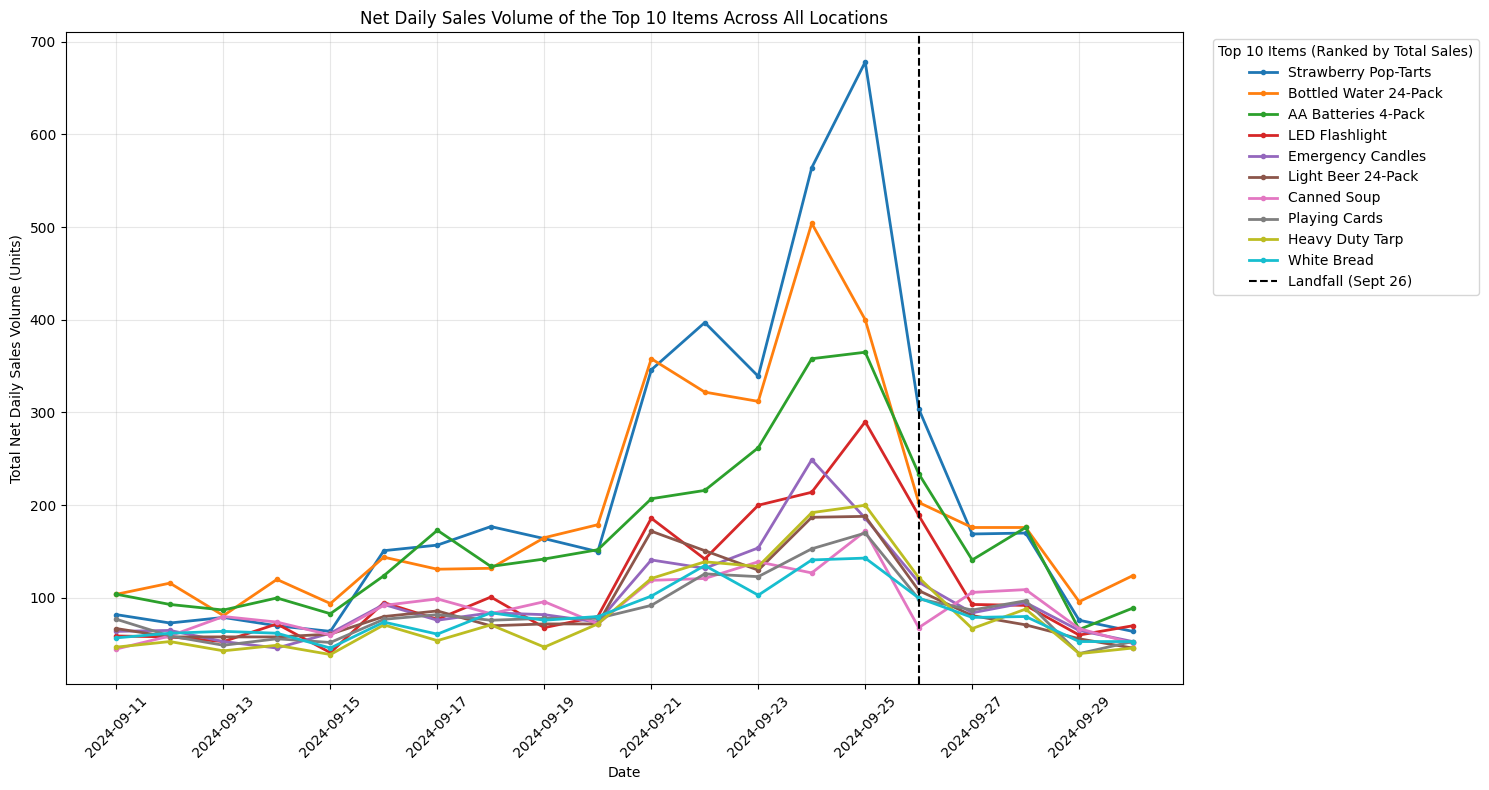

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

WEATHER_START = "2024-09-11"
WEATHER_END = "2024-10-01"

# Ensuring the clean transactions are recognized
assert len(transactions_clean) > 0, ("transactions_clean is empty, the data files didn't load in this session")

# Copy your sales data
sales = transactions_clean.copy()

# Establishing start and end date for the graph (10/01 is excluded)
start = pd.Timestamp(WEATHER_START).date()
end = pd.Timestamp(WEATHER_END).date()

# Extract the date from cleaned local timestamp, dropping NaTs
sales = sales.dropna(subset=["timestamp_local"]).copy()
sales["date"] = sales["timestamp_local"].dt.date

sales = sales[(sales["date"] >= start) & (sales["date"] < end)].copy()

# Ensuring clean sales data is recognized
assert len(sales) > 0, "no sales fall in the date range after parsing"

# Grouping net sales by item and date
item_daily_sales = (sales.groupby(["date", "product_name"])["quantity"].sum().reset_index())

all_dates = pd.date_range(
    start=WEATHER_START,
    end=WEATHER_END,
    inclusive="left",
    freq="D"
).date

fig, ax = plt.subplots(figsize=(15, 8))

#Pull total product sales
product_totals = (item_daily_sales.groupby("product_name")["quantity"].sum().sort_values(ascending=False))

# Select the top 10 best-selling items
top10_items = product_totals.head(10).index

# Plot the top ten and order from most sold to least sold
for item in top10_items:
    group = item_daily_sales[item_daily_sales["product_name"] == item]
    daily = group.set_index("date")["quantity"].reindex(all_dates, fill_value=0)
    ax.plot(all_dates, daily, marker="o", linewidth=2, markersize=3, label=item)

# Mark landfall on the graph
LANDFALL = pd.Timestamp("2024-09-26")
ax.axvline(LANDFALL, color="black", linestyle="--", label="Landfall (Sept 26)")

# Set axis and legend labels
ax.set_title("Net Daily Sales Volume of the Top 10 Items Across All Locations")
ax.set_xlabel("Date")
ax.set_ylabel("Total Net Daily Sales Volume (Units)")
ax.legend(title="Top 10 Items (Ranked by Total Sales)", bbox_to_anchor=(1.02, 1), loc="upper left")

ax.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **Q3: Weather Correlation**

> Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

built on `store_day_weather` and `category_day_weather` from the weather section, nothing re-pulled
- main unit of analysis is the statewide day: total units across all 12 stores vs weather averaged over the 12 store sites, so n = 30 days
- pearson for the headline numbers, spearman (rank) alongside it since one storm dominates the month
- lag = weather k days *after* the sales day, k from -3 to +5. positive k means sales move first
- every correlation prints its n, a lagged correlation loses k days off the end of september
- per-store check: how many days each store's sales peak came before its own worst weather, 12 separate readings of the lag
- wind stays in km/h like the rest of the notebook

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

WEATHER_COLUMNS = ["precipitation_mm", "max_wind_kmh", "min_pressure_hpa"]
WEATHER_LABELS = {"precipitation_mm": "rain (mm)", "max_wind_kmh": "max wind (km/h)", "min_pressure_hpa": "min pressure (hPa)"}
LANDFALL = pd.Timestamp("2024-09-26")

# q3 only uses real api rows, no gaps
assert store_day_weather["has_weather"].all(), "some store-days have no weather"
assert store_day_weather["source"].eq("open-meteo").all(), "weather is not all live api data"

# statewide day: sum units over stores, average weather over store sites
statewide = store_day_weather.groupby("date").agg(
    units=("units", "sum"),
    **{column: (column, "mean") for column in WEATHER_COLUMNS},
)
statewide["units"] = statewide["units"].astype("float64")
assert len(statewide) == 30 and statewide.notna().all().all()

# normalize_category leaves these two as their own labels, fold them in here so q3 has 10 categories
CATEGORY_FIXES = {"Games & Entertainment": "Entertainment", "Health & Wellness": "Health"}
category_daily = (
    category_day_weather.assign(category=category_day_weather["category"].replace(CATEGORY_FIXES))
    .groupby(["date", "category"])["units"].sum().unstack().astype("float64")
)
assert category_daily.shape == (30, 10), category_daily.shape
assert category_daily.sum().sum() == statewide["units"].sum(), "category split lost units"

print(f"statewide days: {len(statewide)}, categories: {category_daily.shape[1]}, weather source: open-meteo (live)")
display(statewide.round(1))

statewide days: 30, categories: 10, weather source: open-meteo (live)


,units,precipitation_mm,max_wind_kmh,min_pressure_hpa
date,,,,
2024-09-01,1060.0,8.3,16.2,1012.4
2024-09-02,1168.0,7.5,14.0,1012.5
2024-09-03,1162.0,13.6,17.3,1013.9
2024-09-04,1115.0,14.5,17.5,1016.3
2024-09-05,1076.0,11.4,16.6,1014.9
2024-09-06,1104.0,11.4,15.4,1012.3
2024-09-07,1086.0,5.5,12.9,1010.4
2024-09-08,1097.0,17.3,14.8,1012.1
2024-09-09,1084.0,12.6,15.4,1014.3


In [16]:
# same day: units vs that day's weather
same_day = pd.DataFrame({
    "pearson_r": [statewide["units"].corr(statewide[c]) for c in WEATHER_COLUMNS],
    "spearman_r": [statewide["units"].corr(statewide[c], method="spearman") for c in WEATHER_COLUMNS],
    "n_days": len(statewide),
}, index=[WEATHER_LABELS[c] for c in WEATHER_COLUMNS]).round(2)
display(same_day)

,pearson_r,spearman_r,n_days
rain (mm),-0.30,-0.23,30
max wind (km/h),0.23,0.34,30
min pressure (hPa),-0.24,-0.40,30


In [17]:
# lagged: units on day t vs weather on day t + k
LAGS = range(-3, 6)

def lagged_corr(series, weather, k, method="pearson"):
    shifted = weather.shift(-k)
    keep = shifted.notna()
    return series[keep].corr(shifted[keep], method=method), int(keep.sum())

lag_rows = []
for k in LAGS:
    row = {"lag_days": k}
    for column in WEATHER_COLUMNS:
        row[WEATHER_LABELS[column]], row["n_days"] = lagged_corr(statewide["units"], statewide[column], k)
        row[WEATHER_LABELS[column] + " (spearman)"] = lagged_corr(statewide["units"], statewide[column], k, "spearman")[0]
    lag_rows.append(row)
lag_table = pd.DataFrame(lag_rows).set_index("lag_days").round(2)
display(lag_table)

best_lag = int(lag_table[WEATHER_LABELS["max_wind_kmh"]].idxmax())
print(f"strongest wind correlation at lag {best_lag:+d} days: "
      f"r = {lag_table.loc[best_lag, WEATHER_LABELS['max_wind_kmh']]:+.2f}, "
      f"pressure r = {lag_table.loc[best_lag, WEATHER_LABELS['min_pressure_hpa']]:+.2f}, "
      f"n = {lag_table.loc[best_lag, 'n_days']} days")

# same check per store-day (stores share one storm, so these are not independent)
by_store = store_day_weather.sort_values(["store_id", "date"]).copy()
by_store["units"] = by_store["units"].astype("float64")
shifted = by_store.groupby("store_id")[WEATHER_COLUMNS].shift(-best_lag)
keep = shifted.notna().all(axis=1)
print(f"store-day level at lag {best_lag:+d}: " + ", ".join(
    f"{WEATHER_LABELS[c]} r = {by_store.loc[keep, 'units'].corr(shifted.loc[keep, c]):+.2f}" for c in WEATHER_COLUMNS
) + f", n = {int(keep.sum())} store-days")

,rain (mm),n_days,rain (mm) (spearman),max wind (km/h),max wind (km/h) (spearman),min pressure (hPa),min pressure (hPa) (spearman)
lag_days,,,,,,,
-3,-0.62,27,-0.57,-0.24,-0.47,0.03,-0.21
-2,-0.61,28,-0.50,-0.11,-0.16,-0.06,-0.23
-1,-0.58,29,-0.59,0.04,-0.04,-0.13,-0.27
0,-0.30,30,-0.23,0.23,0.34,-0.24,-0.40
1,0.01,29,-0.27,0.58,0.24,-0.59,-0.46
2,0.02,28,-0.33,0.80,0.25,-0.80,-0.38
3,-0.06,27,-0.43,0.61,0.24,-0.62,-0.48
4,-0.03,26,-0.35,0.42,0.30,-0.43,-0.42
5,-0.10,25,-0.30,0.34,0.19,-0.36,-0.19


strongest wind correlation at lag +2 days: r = +0.80, pressure r = -0.80, n = 28 days
store-day level at lag +2: rain (mm) r = +0.01, max wind (km/h) r = +0.69, min pressure (hPa) r = -0.72, n = 336 store-days


In [18]:
# per store: days from the sales peak to that store's own windiest day and lowest pressure
peak_rows = []
for store_id, group in store_day_weather.groupby("store_id"):
    group = group.set_index("date")
    sales_peak = group["units"].idxmax()
    wind_peak = group["max_wind_kmh"].idxmax()
    pressure_low = group["min_pressure_hpa"].idxmin()
    peak_rows.append({
        "store_id": store_id,
        "sales_peak": sales_peak.date(),
        "windiest_day": wind_peak.date(),
        "lowest_pressure_day": pressure_low.date(),
        "days_before_wind_peak": (wind_peak - sales_peak).days,
        "days_before_pressure_low": (pressure_low - sales_peak).days,
        "max_wind_kmh": group["max_wind_kmh"].max(),
        "min_pressure_hpa": group["min_pressure_hpa"].min(),
    })
store_peaks = (pd.DataFrame(peak_rows)
               .merge(stores[["store_id", "city"]], on="store_id", how="left", validate="one_to_one")
               .set_index("store_id"))
display(store_peaks)

lead_p = store_peaks["days_before_pressure_low"]
lead_w = store_peaks["days_before_wind_peak"]
print(f"sales peaked before the lowest pressure at {int(lead_p.gt(0).sum())} of {len(lead_p)} stores, "
      f"by {lead_p.min()}-{lead_p.max()} days (median {lead_p.median():.0f})")
print(f"sales peaked 1-3 days before the windiest day at {int(lead_w.between(1, 3).sum())} of {len(lead_w)} stores")
odd = store_peaks.loc[~lead_w.between(1, 3)]
if len(odd) > 0:
    print("windiest day outside the helene window:", odd[["city", "windiest_day", "max_wind_kmh"]].to_dict("index"))

,sales_peak,windiest_day,lowest_pressure_day,days_before_wind_peak,days_before_pressure_low,max_wind_kmh,min_pressure_hpa,city
store_id,,,,,,,,
FL-078,2024-09-25,2024-09-27,2024-09-26,2,1,52.9,990.3,Gainesville
FL-105,2024-09-25,2024-09-26,2024-09-26,1,1,70.1,993.5,Tampa
FL-156,2024-09-24,2024-09-26,2024-09-26,2,2,46.2,998.5,Daytona Beach
FL-239,2024-09-24,2024-09-26,2024-09-26,2,2,47.7,998.3,Orlando
FL-287,2024-09-25,2024-09-26,2024-09-26,1,1,46.4,998.8,Kissimmee
FL-302,2024-09-25,2024-09-26,2024-09-26,1,1,46.7,997.0,Lakeland
FL-330,2024-09-24,2024-09-26,2024-09-26,2,2,47.7,1005.6,Miami
FL-412,2024-09-25,2024-09-27,2024-09-27,2,2,61.2,992.5,Jacksonville
FL-445,2024-09-24,2024-09-26,2024-09-26,2,2,76.4,992.7,St. Petersburg


sales peaked before the lowest pressure at 12 of 12 stores, by 1-3 days (median 2)
sales peaked 1-3 days before the windiest day at 11 of 12 stores
windiest day outside the helene window: {'FL-710': {'city': 'Pensacola', 'windiest_day': datetime.date(2024, 9, 12), 'max_wind_kmh': 43.9}}


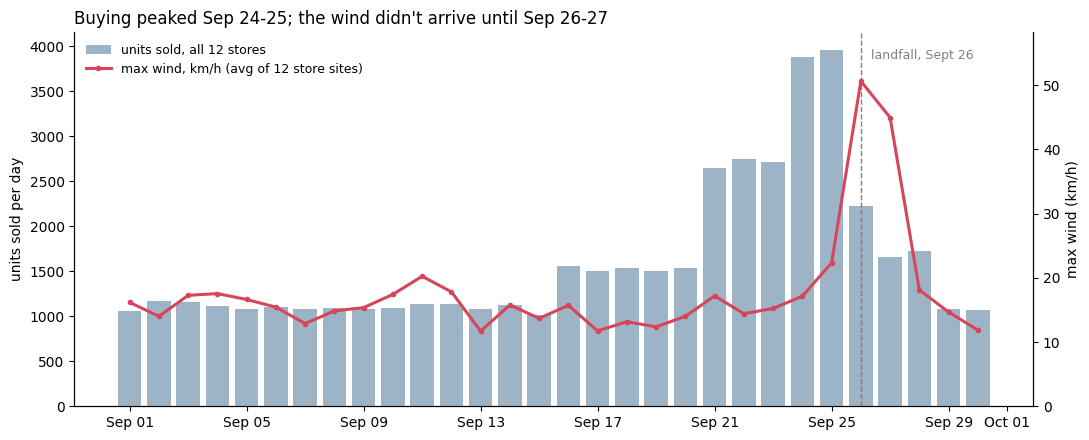

In [19]:
# chart 1: daily units with wind on a second axis
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(statewide.index, statewide["units"], color="#9db4c6", width=0.8, label="units sold, all 12 stores")
ax.set_ylabel("units sold per day")
ax2 = ax.twinx()
ax2.plot(statewide.index, statewide["max_wind_kmh"], color="#d6455a", lw=2.2, marker="o", ms=3,
         label="max wind, km/h (avg of 12 store sites)")
ax2.set_ylabel("max wind (km/h)")
ax2.set_ylim(0, statewide["max_wind_kmh"].max() * 1.15)
ax.axvline(LANDFALL, ls="--", color="gray", lw=1)
ax.annotate("landfall, Sept 26", xy=(LANDFALL + pd.Timedelta(hours=8), ax.get_ylim()[1] * 0.93), fontsize=9, color="gray")
top_sales = sorted(statewide["units"].nlargest(2).index)
top_wind = sorted(statewide["max_wind_kmh"].nlargest(2).index)
ax.set_title(f"Buying peaked {top_sales[0]:%b %d}-{top_sales[1]:%d}; the wind didn't arrive until "
             f"{top_wind[0]:%b %d}-{top_wind[1]:%d}", loc="left", fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, [h.get_label() for h in handles], frameon=False, fontsize=9, loc="upper left")
for axis in (ax, ax2):
    axis.spines["top"].set_visible(False)
plt.tight_layout()
plt.show()

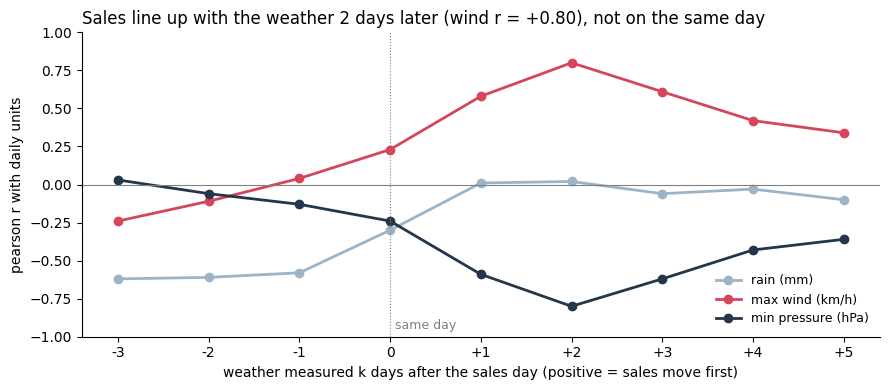

n per lag: {-3: 27, -2: 28, -1: 29, 0: 30, 1: 29, 2: 28, 3: 27, 4: 26, 5: 25}


In [20]:
# chart 2: correlation at each lag
fig, ax = plt.subplots(figsize=(9, 4))
colors = {"max_wind_kmh": "#d6455a", "min_pressure_hpa": "#24364a", "precipitation_mm": "#9db4c6"}
for column in WEATHER_COLUMNS:
    label = WEATHER_LABELS[column]
    ax.plot(lag_table.index, lag_table[label], marker="o", color=colors[column], lw=2, label=label)
ax.axhline(0, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8, ls=":")
ax.annotate("same day", xy=(0.05, -0.95), fontsize=9, color="gray")
ax.set_xticks(list(LAGS))
ax.set_xticklabels([f"{k:+d}" if k else "0" for k in LAGS])
ax.set_xlabel("weather measured k days after the sales day (positive = sales move first)")
ax.set_ylabel("pearson r with daily units")
ax.set_ylim(-1, 1)
ax.set_title(f"Sales line up with the weather {best_lag} days later (wind r = "
             f"{lag_table.loc[best_lag, WEATHER_LABELS['max_wind_kmh']]:+.2f}), not on the same day",
             loc="left", fontsize=12)
ax.legend(frameon=False, fontsize=9, loc="lower right")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()
print("n per lag:", lag_table["n_days"].to_dict())

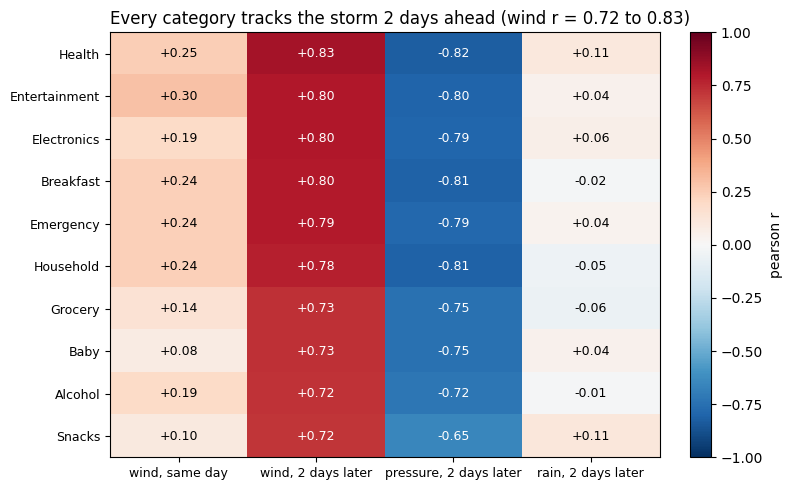

n = 30 days same day, 28 days lagged


In [21]:
# chart 3: every category, same day vs the best lag
measures = {
    "wind, same day": statewide["max_wind_kmh"],
    f"wind, {best_lag} days later": statewide["max_wind_kmh"].shift(-best_lag),
    f"pressure, {best_lag} days later": statewide["min_pressure_hpa"].shift(-best_lag),
    f"rain, {best_lag} days later": statewide["precipitation_mm"].shift(-best_lag),
}
category_corr = pd.DataFrame({
    name: {category: category_daily[category].corr(weather) for category in category_daily.columns}
    for name, weather in measures.items()
}).sort_values(f"wind, {best_lag} days later", ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(category_corr.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(category_corr.columns)))
ax.set_xticklabels(category_corr.columns, fontsize=9)
ax.set_yticks(range(len(category_corr.index)))
ax.set_yticklabels(category_corr.index, fontsize=9)
for (i, j), value in np.ndenumerate(category_corr.values):
    ax.text(j, i, f"{value:+.2f}", ha="center", va="center", fontsize=9,
            color="white" if abs(value) > 0.6 else "black")
wind_lag = category_corr[f"wind, {best_lag} days later"]
ax.set_title(f"Every category tracks the storm {best_lag} days ahead "
             f"(wind r = {wind_lag.min():.2f} to {wind_lag.max():.2f})", loc="left", fontsize=12)
fig.colorbar(image, ax=ax, fraction=0.04, label="pearson r")
plt.tight_layout()
plt.show()
print(f"n = {len(statewide)} days same day, {len(statewide) - best_lag} days lagged")

**Q3 answer:**

**Same day, the weather barely moves sales.** Across the 30 days of September, daily units correlate weakly with that day's weather: wind r = +0.23, pressure r = −0.24, rain r = −0.30. On landfall day itself (Sept 26), with the strongest wind and lowest pressure of the month, sales were already falling.

**Two days ahead, the relationship is strong: there is a detectable lag of about two days.** Sales line up with the weather 2 days *later*: wind r = +0.80 and pressure r = −0.80 (n = 28 days). The store-by-store check agrees. Every one of the 12 stores sold the most 1–3 days before its own lowest pressure (median 2 days), and 11 of 12 sold the most 1–3 days before their own windiest day. The exception is Pensacola, whose windiest day was Sept 12, during Hurricane Francine's landfall in Louisiana, and its sales did not surge then. That supports the reading that people buy on the forecast, not on the weather outside. All 10 categories follow the same two-day lead (wind r = 0.72 to 0.83), so this is the whole basket moving with one storm, not some categories being more weather-sensitive than others.

**Rain is not a useful indicator.** It is near zero at every positive lag. The negative correlation with rain in the days *before* a sale (r ≈ −0.6) is timing, not cause: the week before Helene happened to be dry (under 1 mm a day from Sept 19–24) while the surge was building.

**Caveats:**
- This is one month and one storm. The rank (spearman) correlations at the 2-day lag are much weaker (wind +0.25, pressure −0.38), which means the strong pearson r comes from the storm days themselves, not from a steady relationship on ordinary days.
- So the 0.80 describes Helene's timing, not a model to forecast sales from weather.
- Statewide weather is an average of 12 store sites. The store-day version (n = 336, not independent because every store saw the same storm) gives the same picture: wind r = +0.69, pressure r = −0.72 at the 2-day lag.

**For Walmart:** don't wait for the weather to turn. The buying happens on the forecast, about two days before the worst conditions, so stock has to be on the shelves before then.

In [22]:
# q3 decisions and how many rows each one touched
q3_decision_log = pd.DataFrame([
    ("q3 unit of analysis", "statewide day: units summed over 12 stores, weather averaged over the 12 store sites", len(statewide)),
    ("q3 category labels", "folded 'Games & Entertainment' into Entertainment and 'Health & Wellness' into Health (normalize_category misses them)",
     int(category_day_weather["category"].isin(CATEGORY_FIXES).sum())),
    ("q3 lag direction", "lag k = weather k days after the sales day, k from -3 to +5, n printed for each", len(lag_table)),
    ("q3 correlation method", "pearson for headline numbers, spearman alongside because one storm dominates the month", len(WEATHER_COLUMNS)),
    ("q3 per-store lag", "each store's sales peak vs its own windiest and lowest-pressure day", len(store_peaks)),
], columns=["decision", "what_it_did", "rows_touched"])
display(q3_decision_log)

,decision,what_it_did,rows_touched
0,q3 unit of analysis,"statewide day: units summed over 12 stores, we...",30
1,q3 category labels,folded 'Games & Entertainment' into Entertainm...,472
2,q3 lag direction,"lag k = weather k days after the sales day, k ...",9
3,q3 correlation method,"pearson for headline numbers, spearman alongsi...",3
4,q3 per-store lag,each store's sales peak vs its own windiest an...,12
